# 01 · Khám phá dữ liệu (EDA)
## Hành vi đặt hàng, giỏ hàng, sản phẩm và mua lại trong bán lẻ trực tuyến

**Dữ liệu (6 bảng):** `orders`, `order_products__prior`, `order_products__train`, `products`, `aisles`, `departments`

| Mục | Nội dung |
|---|---|
| 1 | Tổng quan bảng: số dòng, kiểu dữ liệu, số người dùng, số đơn, số sản phẩm, gian hàng, ngành hàng |
| 2 | Hành vi đặt hàng: số đơn mỗi người dùng · bản đồ nhiệt `order_dow` × `order_hour_of_day` · chu kỳ quay lại và đỉnh bất thường |
| 3 | Phân phối kích thước giỏ hàng |
| 4 | Sản phẩm, gian hàng, ngành hàng được mua nhiều nhất |
| 5 | Tỷ lệ mua lại theo ngành hàng và theo `add_to_cart_order` |
| 6 | Cột reordered và nhãn phân lớp của Bước 5 |
| 7 | Tổng hợp nhận xét và hạn chế |

**Cách chạy:** đặt đủ 6 tệp CSV vào `data/raw/` của repo, sửa `REPO_DIR` ở ô Cấu hình nếu cần, rồi chọn *Runtime, Restart and run all*. Notebook dừng ngay nếu thiếu tệp, kể cả `order_products__prior.csv`.
Hình lưu ở `reports/figures/eda/`, số liệu tóm tắt lưu ở `outputs/step1/eda_summary.json`. Ô cuối đối chiếu các con số chính với Chương 4 mục 2 của báo cáo.

**Về phần nhận xét:** sau mỗi bảng/biểu đồ có một ô *Nhận xét* được **sinh trực tiếp từ số liệu vừa tính** (không gõ tay con số), kèm diễn giải nghiệp vụ bán lẻ.

> "Được mua nhiều" được đo bằng **số dòng sản phẩm trong các đơn của bảng giao dịch**, không phải doanh thu (dữ liệu không có giá bán).

## 0. Thiết lập môi trường và nạp dữ liệu

In [18]:
from pathlib import Path
import json, warnings
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

C_MAIN, C_ACCENT, C_GREY = '#1F4E78', '#C00000', '#7F7F7F'

In [19]:
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# Thư mục gốc của repo, dùng chung cho cả năm notebook
REPO_DIR = Path(os.environ.get("REPO_DIR", "/content/drive/MyDrive/Nhom04_ADM/repo" if IN_COLAB else ".."))
DATA_DIR = REPO_DIR / "data" / "raw"
PROC_DIR = REPO_DIR / "data" / "processed"
FIG_DIR = REPO_DIR / "reports" / "figures" / "eda"
OUT_DIR = REPO_DIR / "outputs" / "step1"
FIG_DIR.mkdir(parents=True, exist_ok=True); OUT_DIR.mkdir(parents=True, exist_ok=True)

CAN_CO = ["orders.csv", "order_products__prior.csv", "order_products__train.csv",
          "products.csv", "aisles.csv", "departments.csv"]
thieu = [f for f in CAN_CO if not (DATA_DIR / f).exists()]
if thieu:
    raise FileNotFoundError(f"Thiếu {thieu} trong {DATA_DIR}. EDA phải chạy trên bảng prior, không chạy tạm trên bảng train.")
print("Thư mục dữ liệu:", DATA_DIR.resolve())


def pct(val, decimals=1):
    return f"{val * 100:.{decimals}f}%"

def fmt_k(x, pos):
    return f'{x*1e-3:.0f}k' if x >= 1e3 else f'{x:.0f}'

def fmt_mk(x, pos):
    return f'{x*1e-3:.0f}k' if x >= 1e3 else f'{x:.0f}'

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches='tight', dpi=150)

def note(text):
    display(Markdown(text))

R = {}

op_dtype = {"order_id": "int32", "product_id": "int32", "add_to_cart_order": "int16", "reordered": "int8"}
orders = pd.read_csv(DATA_DIR / "orders.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
aisles = pd.read_csv(DATA_DIR / "aisles.csv")
departments = pd.read_csv(DATA_DIR / "departments.csv")
op_train = pd.read_csv(DATA_DIR / "order_products__train.csv", dtype=op_dtype)
op = pd.read_csv(DATA_DIR / "order_products__prior.csv", dtype=op_dtype)   # bảng giao dịch chính
HAS_PRIOR, TX = True, "prior"
print(f"orders {orders.shape} | prior {op.shape} | train {op_train.shape}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Thư mục dữ liệu: /content/drive/MyDrive/Nhom04_ADM/repo/data/raw
orders (3421083, 7) | prior (32434489, 4) | train (1384617, 4)


**Ghi chú dữ liệu:** `order_products__prior` là bảng giao dịch chính (khớp với các đơn `eval_set = 'prior'` của `orders`); `order_products__train` dùng cho tổng quan và đối chiếu nhãn. File trùng như `orders_1.csv` (giống hệt `orders.csv`) chỉ dùng một bản. `order_dow` chỉ có mã số; bộ dữ liệu không công bố mã 0 ứng với thứ mấy, nên notebook và báo cáo giữ nguyên ký hiệu `order_dow`.

## 1. Tổng quan bảng

In [20]:
tables = {'orders': orders, 'order_products (train)': op_train, 'products': products,
          'aisles': aisles, 'departments': departments}
if HAS_PRIOR:
    tables = {'orders': orders, 'order_products (prior)': op, **{k: v for k, v in tables.items() if k != 'orders'}}

def n_dup(t):
    if 'add_to_cart_order' in t.columns:      # đếm trùng cặp (order_id, product_id) bằng khóa số nguyên cho nhanh
        return int(len(t) - np.unique(t['order_id'].astype('int64') * 100_000 + t['product_id']).size)
    return int(t.duplicated().sum())

overview = pd.DataFrame([{'Bảng': n, 'Số dòng': len(t), 'Số cột': t.shape[1],
                          'Missing': int(t.isna().sum().sum()), 'Dòng trùng': n_dup(t)} for n, t in tables.items()]).set_index('Bảng')
display(overview.style.format('{:,}'))

display(pd.Series({n: ', '.join(f'{c}:{t[c].dtype}' for c in t.columns) for n, t in tables.items()},
                  name='Kiểu dữ liệu từng cột').to_frame())
print('Missing theo cột của bảng orders:')
display(orders.isna().sum().rename('Missing').to_frame())

,Số dòng,Số cột,Missing,Dòng trùng
Bảng,,,,
orders,"3,421,083",7,"206,209",0
order_products (prior),"32,434,489",4,0,0
order_products (train),"1,384,617",4,0,0
products,"49,688",4,0,0
aisles,134,2,0,0
departments,21,2,0,0


,Kiểu dữ liệu từng cột
orders,"order_id:int64, user_id:int64, eval_set:object, order_number:int64, order_dow:int64, order_hour_of_day:int64, days_since_prior_order:float64"
order_products (prior),"order_id:int32, product_id:int32, add_to_cart_order:int16, reordered:int8"
order_products (train),"order_id:int32, product_id:int32, add_to_cart_order:int16, reordered:int8"
products,"product_id:int64, product_name:object, aisle_id:int64, department_id:int64"
aisles,"aisle_id:int64, aisle:object"
departments,"department_id:int64, department:object"


Missing theo cột của bảng orders:


,Missing
order_id,0
user_id,0
eval_set,0
order_number,0
order_dow,0
order_hour_of_day,0
days_since_prior_order,206209


In [21]:
counts = {
    'Số người dùng (user_id duy nhất)':             orders['user_id'].nunique(),
    'Số đơn hàng (order_id duy nhất, bảng orders)': orders['order_id'].nunique(),
    'Số sản phẩm trong danh mục':                   products['product_id'].nunique(),
    'Số gian hàng (aisle)':                         aisles['aisle_id'].nunique(),
    'Số ngành hàng (department)':                   departments['department_id'].nunique(),
    f'Số đơn trong order_products ({TX})':          op['order_id'].nunique(),
    f'Số dòng trong order_products ({TX})':         len(op),
    f'Số sản phẩm khác nhau xuất hiện trong {TX}':  op['product_id'].nunique(),
    'Số đơn / dòng trong order_products (train)':   f"{op_train['order_id'].nunique():,} / {len(op_train):,}",
}
eval_cnt = orders['eval_set'].value_counts()
display(pd.Series({k: (f'{v:,}' if not isinstance(v, str) else v) for k, v in counts.items()}, name='Giá trị').to_frame())
print('Số đơn theo eval_set (prior / train / test):', {k: int(eval_cnt.get(k, 0)) for k in ['prior', 'train', 'test']})

checks = {
    'train khớp hoàn toàn với đơn eval_set=train của orders': set(op_train['order_id']) == set(orders.loc[orders['eval_set'] == 'train', 'order_id']),
    f'mọi product_id trong {TX} đều có trong products':        bool(np.isin(op['product_id'].unique(), products['product_id']).all()),
    'mọi aisle_id của products đều có trong aisles':           bool(products['aisle_id'].isin(aisles['aisle_id']).all()),
    'mọi department_id của products đều có trong departments': bool(products['department_id'].isin(departments['department_id']).all()),
}
if HAS_PRIOR:
    checks['prior khớp hoàn toàn với đơn eval_set=prior của orders'] = set(op['order_id']) == set(orders.loc[orders['eval_set'] == 'prior', 'order_id'])
display(pd.Series(checks, name='Đạt?').to_frame())

n_users, n_orders = orders['user_id'].nunique(), orders['order_id'].nunique()
miss_days = int(orders['days_since_prior_order'].isna().sum())
R['overview'] = {'users': n_users, 'orders': n_orders, 'orders_per_user': n_orders / n_users, 'products': len(products),
                 'aisles': len(aisles), 'departments': len(departments), 'products_per_aisle': len(products) / len(aisles),
                 'tx_rows': len(op), 'tx_orders': op['order_id'].nunique(), 'rows_per_order': len(op) / op['order_id'].nunique(),
                 'distinct_products_in_tx': int(op['product_id'].nunique()), 'missing_days': miss_days,
                 'total_missing': int(sum(t.isna().sum().sum() for t in tables.values())),
                 'total_dups': int(overview['Dòng trùng'].sum()), 'checks': checks}

note(f'''
**Nhận xét.** Bộ dữ liệu có **{n_users:,} người dùng** và **{n_orders:,} đơn**, trung bình **{n_orders/n_users:.2f} đơn/người**. Danh mục gồm **{len(products):,} sản phẩm**, **{len(aisles)} gian hàng** ({len(products)/len(aisles):.1f} sản phẩm/gian) và **{len(departments)} ngành hàng**; bảng {TX} có {len(op):,} dòng cho {op['order_id'].nunique():,} đơn, tức **{len(op)/op['order_id'].nunique():.2f} dòng sản phẩm/đơn**.
Tổng giá trị thiếu của mọi bảng là **{R['overview']['total_missing']:,}** và tổng dòng trùng là **{R['overview']['total_dups']:,}**. Riêng `days_since_prior_order` thiếu {miss_days:,} giá trị{' — đúng bằng số người dùng' if miss_days == n_users else ''}, vì đó là *đơn đầu tiên* của mỗi người (chưa có đơn trước) nên là thiếu có chủ đích, không phải lỗi dữ liệu.
*Diễn giải bán lẻ:* quy mô vài trăm nghìn khách với hàng chục nghìn mã hàng cho thấy đây là bài toán bán lẻ tạp hóa trực tuyến tần suất cao; dữ liệu sạch (không trùng, khóa khớp) nên có thể chuyển thẳng sang phân tích hành vi mà không cần dọn nhiều.
''')

,Giá trị
Số người dùng (user_id duy nhất),"206,209"
"Số đơn hàng (order_id duy nhất, bảng orders)","3,421,083"
Số sản phẩm trong danh mục,"49,688"
Số gian hàng (aisle),134
Số ngành hàng (department),21
Số đơn trong order_products (prior),"3,214,874"
Số dòng trong order_products (prior),"32,434,489"
Số sản phẩm khác nhau xuất hiện trong prior,"49,677"
Số đơn / dòng trong order_products (train),"131,209 / 1,384,617"


Số đơn theo eval_set (prior / train / test): {'prior': 3214874, 'train': 131209, 'test': 75000}


,Đạt?
train khớp hoàn toàn với đơn eval_set=train của orders,True
mọi product_id trong prior đều có trong products,True
mọi aisle_id của products đều có trong aisles,True
mọi department_id của products đều có trong departments,True
prior khớp hoàn toàn với đơn eval_set=prior của orders,True



**Nhận xét.** Bộ dữ liệu có **206,209 người dùng** và **3,421,083 đơn**, trung bình **16.59 đơn/người**. Danh mục gồm **49,688 sản phẩm**, **134 gian hàng** (370.8 sản phẩm/gian) và **21 ngành hàng**; bảng prior có 32,434,489 dòng cho 3,214,874 đơn, tức **10.09 dòng sản phẩm/đơn**.
Tổng giá trị thiếu của mọi bảng là **206,209** và tổng dòng trùng là **0**. Riêng `days_since_prior_order` thiếu 206,209 giá trị — đúng bằng số người dùng, vì đó là *đơn đầu tiên* của mỗi người (chưa có đơn trước) nên là thiếu có chủ đích, không phải lỗi dữ liệu.
*Diễn giải bán lẻ:* quy mô vài trăm nghìn khách với hàng chục nghìn mã hàng cho thấy đây là bài toán bán lẻ tạp hóa trực tuyến tần suất cao; dữ liệu sạch (không trùng, khóa khớp) nên có thể chuyển thẳng sang phân tích hành vi mà không cần dọn nhiều.


## 2. Hành vi đặt hàng

### 2.1 Phân phối số đơn mỗi người dùng (`order_number` lớn nhất)

,Số đơn / người dùng
mean,16.5904
median,10.0000
min,4.0000
max,100.0000
p25,6.0000
p75,20.0000
n_at_max,"1,374.0000"
share_le10,0.5068
share_gt20_users,0.2460
share_gt20_orders,0.5874



**Nhận xét (Hình 1).** Trung vị **10 đơn**, trung bình **16.59 đơn**, hệ số bất đối xứng (skewness) 2.40 → phân phối **lệch phải** rõ rệt. Mỗi người có từ **4 đến 100 đơn** (1,374 người chạm trần 100); **50.7%** người dùng có không quá 10 đơn. Nhóm trên 20 đơn chỉ chiếm **24.6%** người dùng nhưng tạo ra **58.7%** tổng số đơn.
*Diễn giải bán lẻ:* số đơn hàng tập trung vào một nhóm khách trung thành nhỏ (dữ liệu không có giá bán nên đây là tần suất đặt hàng, không phải doanh thu); ưu đãi thành viên, giao hàng ưu tiên cho nhóm này nhiều khả năng hiệu quả hơn so với việc kéo thêm khách mới chỉ mua vài đơn.


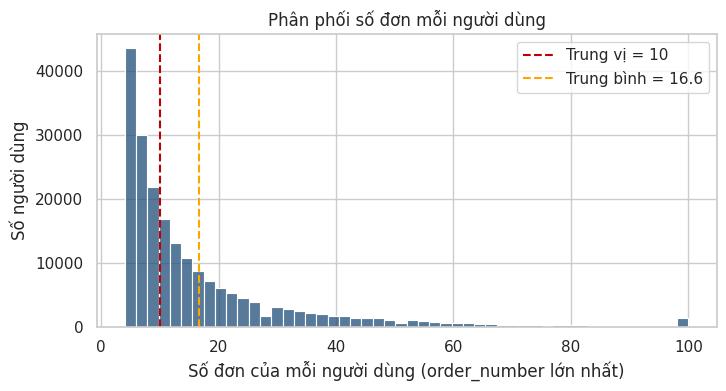

In [22]:
upu = orders.groupby('user_id')['order_number'].max()
R['upu'] = {'mean': upu.mean(), 'median': upu.median(), 'min': int(upu.min()), 'max': int(upu.max()),
            'p25': upu.quantile(.25), 'p75': upu.quantile(.75), 'n_at_max': int((upu == upu.max()).sum()),
            'share_le10': float((upu <= 10).mean()), 'share_gt20_users': float((upu > 20).mean()),
            'share_gt20_orders': float(upu[upu > 20].sum() / upu.sum()), 'skew': upu.skew()}
display(pd.Series(R['upu'], name='Số đơn / người dùng').to_frame())

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(upu, bins=50, color=C_MAIN, ax=ax)
ax.axvline(upu.median(), color=C_ACCENT, ls='--', label=f'Trung vị = {upu.median():.0f}')
ax.axvline(upu.mean(), color='orange', ls='--', label=f'Trung bình = {upu.mean():.1f}')
ax.set_xlabel('Số đơn của mỗi người dùng (order_number lớn nhất)'); ax.set_ylabel('Số người dùng')
ax.set_title('Phân phối số đơn mỗi người dùng'); ax.legend(); savefig('f1_upu')

u = R['upu']
note(f'''
**Nhận xét (Hình 1).** Trung vị **{u['median']:.0f} đơn**, trung bình **{u['mean']:.2f} đơn**, hệ số bất đối xứng (skewness) {u['skew']:.2f} → phân phối **lệch phải** rõ rệt. Mỗi người có từ **{u['min']} đến {u['max']} đơn** ({u['n_at_max']:,} người chạm trần {u['max']}); **{pct(u['share_le10'])}** người dùng có không quá 10 đơn. Nhóm trên 20 đơn chỉ chiếm **{pct(u['share_gt20_users'])}** người dùng nhưng tạo ra **{pct(u['share_gt20_orders'])}** tổng số đơn.
*Diễn giải bán lẻ:* số đơn hàng tập trung vào một nhóm khách trung thành nhỏ (dữ liệu không có giá bán nên đây là tần suất đặt hàng, không phải doanh thu); ưu đãi thành viên, giao hàng ưu tiên cho nhóm này nhiều khả năng hiệu quả hơn so với việc kéo thêm khách mới chỉ mua vài đơn.
''')

### 2.2 Thời điểm đặt hàng: bản đồ nhiệt `order_dow` × `order_hour_of_day`

,% số đơn
order_dow,
0,17.6000
1,17.2000
2,13.7000
3,12.8000
4,12.5000
5,13.3000
6,13.1000



**Nhận xét (Hình 2).** Ba ô đậm nhất là `order_dow` = **1** lúc **10 giờ** (55,671 đơn), `order_dow` = **0** lúc **14 giờ** (54,552 đơn) và `order_dow` = **0** lúc **15 giờ** (53,954 đơn). Hai ngày `order_dow` = 0, 1 chiếm 17.6% và 17.2% số đơn, trong khi mỗi ngày còn lại chỉ 12.5%–13.7%. Khung **9h–16h chiếm 64.9%** số đơn (giờ đỉnh 10h), còn khung **0h–5h chỉ 1.8%**. Ô thấp nhất là `order_dow` = 3 lúc 3 giờ với 654 đơn, so với 55,671 đơn ở ô cao nhất.
*Diễn giải bán lẻ:* nhu cầu dồn vào hai giá trị `order_dow` = 0, 1 và vào ban ngày. Bộ dữ liệu không công bố mã 0 ứng với thứ mấy nên không gọi đây là đầu tuần. Doanh nghiệp có thể ưu tiên nhân sự soạn hàng, tồn kho hàng tươi và ngân sách quảng cáo cho hai giá trị này trong khung 9 giờ đến 16 giờ; khung đêm dùng cho việc không nhạy thời gian (bảo trì, cập nhật danh mục).


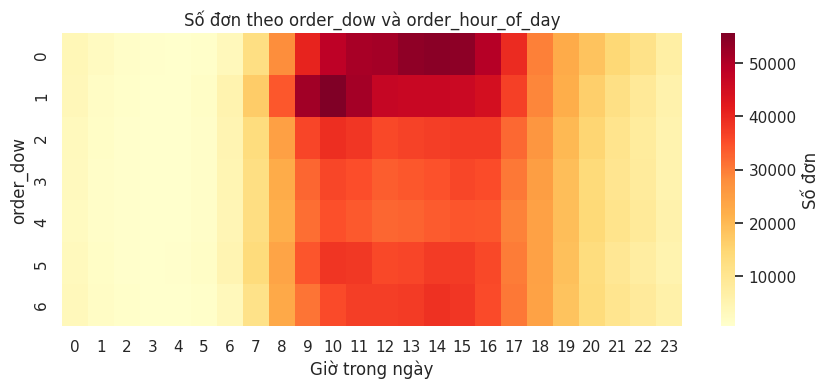

In [23]:
hm = pd.crosstab(orders['order_dow'], orders['order_hour_of_day'])
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(hm, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Số đơn'})
ax.set_title('Số đơn theo order_dow và order_hour_of_day')
ax.set_xlabel('Giờ trong ngày'); ax.set_ylabel('order_dow'); savefig('f2_heat')

st = hm.stack().sort_values(ascending=False)
dow_share = orders['order_dow'].value_counts(normalize=True).sort_index()
h = orders['order_hour_of_day']
R['heat'] = {'top3': [[int(a), int(b), int(v)] for (a, b), v in st.head(3).items()],
             'lowest': [int(st.index[-1][0]), int(st.index[-1][1]), int(st.iloc[-1])],
             'dow_share': dow_share.round(4).to_dict(), 'share_9_16': float(h.between(9, 16).mean()),
             'share_0_5': float(h.between(0, 5).mean()), 'peak_hour': int(h.value_counts().idxmax())}
display(dow_share.mul(100).round(1).rename('% số đơn').to_frame())

hh = R['heat']; top2 = dow_share.sort_values(ascending=False).head(2); rest = dow_share.drop(top2.index)
(a1, b1, v1), (a2, b2, v2), (a3, b3, v3) = hh['top3']
note(f'''
**Nhận xét (Hình 2).** Ba ô đậm nhất là `order_dow` = **{a1}** lúc **{b1} giờ** ({v1:,} đơn), `order_dow` = **{a2}** lúc **{b2} giờ** ({v2:,} đơn) và `order_dow` = **{a3}** lúc **{b3} giờ** ({v3:,} đơn). Hai ngày `order_dow` = {', '.join(map(str, top2.index))} chiếm {' và '.join(pct(v) for v in top2.values)} số đơn, trong khi mỗi ngày còn lại chỉ {pct(rest.min())}–{pct(rest.max())}. Khung **9h–16h chiếm {pct(hh['share_9_16'])}** số đơn (giờ đỉnh {hh['peak_hour']}h), còn khung **0h–5h chỉ {pct(hh['share_0_5'])}**. Ô thấp nhất là `order_dow` = {hh['lowest'][0]} lúc {hh['lowest'][1]} giờ với {hh['lowest'][2]:,} đơn, so với {v1:,} đơn ở ô cao nhất.
*Diễn giải bán lẻ:* nhu cầu dồn vào hai giá trị `order_dow` = {', '.join(map(str, top2.index))} và vào ban ngày. Bộ dữ liệu không công bố mã 0 ứng với thứ mấy nên không gọi đây là đầu tuần. Doanh nghiệp có thể ưu tiên nhân sự soạn hàng, tồn kho hàng tươi và ngân sách quảng cáo cho hai giá trị này trong khung 9 giờ đến 16 giờ; khung đêm dùng cho việc không nhạy thời gian (bảo trì, cập nhật danh mục).
''')

### 2.3 Chu kỳ quay lại: `days_since_prior_order` và các đỉnh bất thường

Các ngày nổi bật nhất so với hai ngày lân cận:


,Số đơn,Gấp (lần)
days_since_prior_order,,
7,"320,608",1.52
14,"100,230",1.34
28,"26,777",1.30
21,"45,470",1.29
1,"145,247",1.11
2,"193,206",1.07



**Nhận xét (Hình 3).** Trung vị **7 ngày**, trung bình **11.11 ngày** (cao hơn vì đuôi phải). Có ba đỉnh bất thường:
- **Đỉnh theo tuần** ở 7, 14, 21, 28 ngày: riêng ngày 7 có 320,608 đơn (10.0%), gấp **1.52 lần** mức trung bình của ngày 6 và 8; ngày 14 gấp 1.34 lần các ngày lân cận. Bốn mốc này cộng lại chiếm **15.3%** số đơn. Đây là **hành vi thật**: khách có thói quen mua theo tuần.
- **Đỉnh ở ngày 30**: 369,323 đơn (11.5%), gấp **19.2 lần** ngày 29 (19,191 đơn). Giá trị lớn nhất của cột là 30, nên mức nhảy vọt này **không phải hành vi tự nhiên** mà do dữ liệu **bị chặn trần tại 30** (censored): "30" nghĩa là *từ 30 ngày trở lên*, không phải chu kỳ 30 ngày. Khi tính trung bình hay dựng mô hình cần xử lý riêng nhóm này.
- **Đơn quay lại rất nhanh**: ngày 0 và ngày 1 chiếm 2.1% và 4.5% — khách đặt thêm ngay trong ngày hoặc hôm sau, thường là mua bổ sung.
*Diễn giải bán lẻ:* đặt lời nhắc mua lại và khuyến mãi quanh ngày thứ 6–7 sau đơn gần nhất; với khách đã qua 21–25 ngày chưa quay lại, kích hoạt ưu đãi giữ chân trước khi họ rơi vào nhóm "30+ ngày".


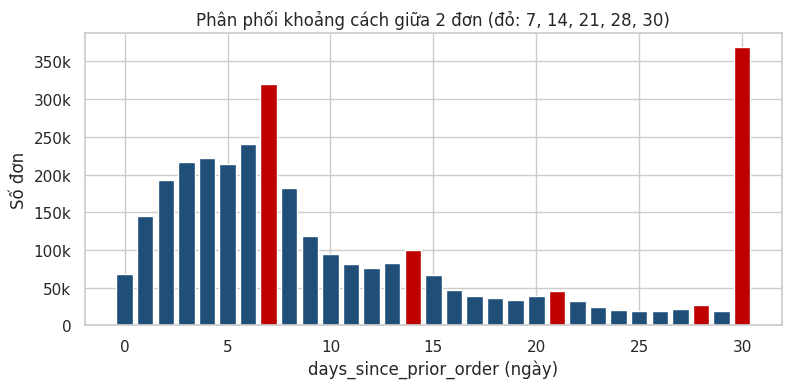

In [24]:
d  = orders['days_since_prior_order'].dropna()
dc = d.value_counts().sort_index().reindex(range(0, 31), fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(dc.index.astype(int), dc.values, color=[C_ACCENT if k in (7, 14, 21, 28, 30) else C_MAIN for k in dc.index])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_k))
ax.set_xlabel('days_since_prior_order (ngày)'); ax.set_ylabel('Số đơn')
ax.set_title('Phân phối khoảng cách giữa 2 đơn (đỏ: 7, 14, 21, 28, 30)'); savefig('f3_days')

tot = dc.sum()
R['days'] = {'n': int(tot), 'mean': d.mean(), 'median': d.median(), 'max_value': float(d.max()),
             'c7': int(dc[7]), 'c14': int(dc[14]), 'c29': int(dc[29]), 'c30': int(dc[30]),
             's7': float(dc[7] / tot), 's30': float(dc[30] / tot), 's0': float(dc[0] / tot), 's1': float(dc[1] / tot),
             'r7': float(dc[7] / ((dc[6] + dc[8]) / 2)), 'r14': float(dc[14] / ((dc[13] + dc[15]) / 2)),
             'r30_29': float(dc[30] / dc[29]), 'weekly_share': float(d.isin([7, 14, 21, 28]).mean())}

# Kiểm tra đỉnh bất thường một cách có hệ thống: so mỗi ngày với trung bình hai ngày lân cận
nb_ = (dc.shift(1) + dc.shift(-1)) / 2
spike = (dc / nb_).dropna().rename('Gấp bao nhiêu lần ngày lân cận').sort_values(ascending=False)
print('Các ngày nổi bật nhất so với hai ngày lân cận:')
display(pd.DataFrame({'Số đơn': dc[spike.index[:6]], 'Gấp (lần)': spike.head(6)}).style.format({'Số đơn': '{:,}', 'Gấp (lần)': '{:.2f}'}))

x = R['days']
note(f'''
**Nhận xét (Hình 3).** Trung vị **{x['median']:.0f} ngày**, trung bình **{x['mean']:.2f} ngày** (cao hơn vì đuôi phải). Có ba đỉnh bất thường:
- **Đỉnh theo tuần** ở 7, 14, 21, 28 ngày: riêng ngày 7 có {x['c7']:,} đơn ({pct(x['s7'])}), gấp **{x['r7']:.2f} lần** mức trung bình của ngày 6 và 8; ngày 14 gấp {x['r14']:.2f} lần các ngày lân cận. Bốn mốc này cộng lại chiếm **{pct(x['weekly_share'])}** số đơn. Đây là **hành vi thật**: khách có thói quen mua theo tuần.
- **Đỉnh ở ngày 30**: {x['c30']:,} đơn ({pct(x['s30'])}), gấp **{x['r30_29']:.1f} lần** ngày 29 ({x['c29']:,} đơn). Giá trị lớn nhất của cột là {x['max_value']:.0f}, nên mức nhảy vọt này **không phải hành vi tự nhiên** mà do dữ liệu **bị chặn trần tại 30** (censored): "30" nghĩa là *từ 30 ngày trở lên*, không phải chu kỳ 30 ngày. Khi tính trung bình hay dựng mô hình cần xử lý riêng nhóm này.
- **Đơn quay lại rất nhanh**: ngày 0 và ngày 1 chiếm {pct(x['s0'])} và {pct(x['s1'])} — khách đặt thêm ngay trong ngày hoặc hôm sau, thường là mua bổ sung.
*Diễn giải bán lẻ:* đặt lời nhắc mua lại và khuyến mãi quanh ngày thứ 6–7 sau đơn gần nhất; với khách đã qua 21–25 ngày chưa quay lại, kích hoạt ưu đãi giữ chân trước khi họ rơi vào nhóm "30+ ngày".
''')

## 3. Phân phối kích thước giỏ hàng (số sản phẩm mỗi đơn)

,Kích thước giỏ hàng (prior)
n,"3,214,874.0000"
mean,10.0889
median,8.0000
mode,5.0000
min,1.0000
max,145.0000
p25,5.0000
p75,14.0000
p95,25.0000
skew,1.5590



**Nhận xét (Hình 4).** Trên 3,214,874 đơn, giỏ trung bình **10.09 sản phẩm**, trung vị **8**, giá trị phổ biến nhất là **5**. Khoảng tứ phân vị là 5–14 sản phẩm; 95% đơn có không quá 25 sản phẩm, giỏ lớn nhất có 145 sản phẩm (hệ số bất đối xứng 1.56, lệch phải). **31.1%** đơn có từ 5 sản phẩm trở xuống, chỉ **9.4%** đơn trên 20 sản phẩm.
*Diễn giải bán lẻ:* đa số là giỏ nhỏ đến vừa, thiên về mua bổ sung hơn là đi chợ cả tuần. Có thể đặt ngưỡng miễn phí giao hàng quanh mức trung bình–trung vị (8–10 sản phẩm) để đẩy các giỏ nhỏ lên, và gợi ý mua kèm ở bước thanh toán.


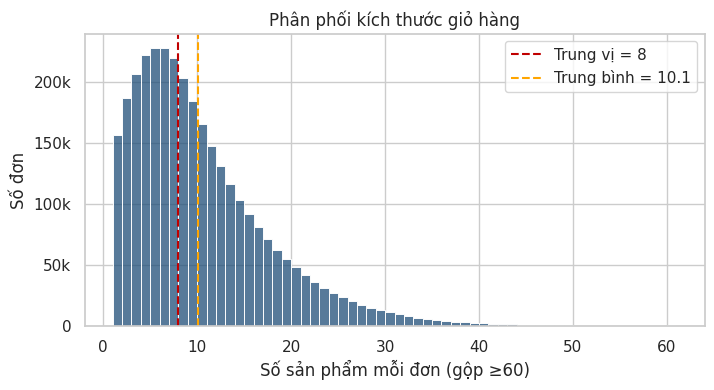

In [25]:
bs = op.groupby('order_id').size()
R['basket'] = {'n': len(bs), 'mean': bs.mean(), 'median': bs.median(), 'mode': int(bs.mode()[0]), 'min': int(bs.min()),
               'max': int(bs.max()), 'p25': bs.quantile(.25), 'p75': bs.quantile(.75), 'p95': bs.quantile(.95),
               'skew': bs.skew(), 'le5': float((bs <= 5).mean()), 'gt20': float((bs > 20).mean())}
display(pd.Series(R['basket'], name=f'Kích thước giỏ hàng ({TX})').to_frame())

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(bs.clip(upper=60), bins=range(1, 62), color=C_MAIN, ax=ax)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_k))
ax.axvline(bs.median(), color=C_ACCENT, ls='--', label=f'Trung vị = {bs.median():.0f}')
ax.axvline(bs.mean(), color='orange', ls='--', label=f'Trung bình = {bs.mean():.1f}')
ax.set_xlabel('Số sản phẩm mỗi đơn (gộp ≥60)'); ax.set_ylabel('Số đơn')
ax.set_title('Phân phối kích thước giỏ hàng'); ax.legend(); savefig('f4_basket')

b = R['basket']
note(f'''
**Nhận xét (Hình 4).** Trên {b['n']:,} đơn, giỏ trung bình **{b['mean']:.2f} sản phẩm**, trung vị **{b['median']:.0f}**, giá trị phổ biến nhất là **{b['mode']}**. Khoảng tứ phân vị là {b['p25']:.0f}–{b['p75']:.0f} sản phẩm; 95% đơn có không quá {b['p95']:.0f} sản phẩm, giỏ lớn nhất có {b['max']} sản phẩm (hệ số bất đối xứng {b['skew']:.2f}, lệch phải). **{pct(b['le5'])}** đơn có từ 5 sản phẩm trở xuống, chỉ **{pct(b['gt20'])}** đơn trên 20 sản phẩm.
*Diễn giải bán lẻ:* đa số là giỏ nhỏ đến vừa, thiên về mua bổ sung hơn là đi chợ cả tuần. Có thể đặt ngưỡng miễn phí giao hàng quanh mức trung bình–trung vị ({b['median']:.0f}–{b['mean']:.0f} sản phẩm) để đẩy các giỏ nhỏ lên, và gợi ý mua kèm ở bước thanh toán.
''')

## 4. Sản phẩm, gian hàng, ngành hàng được mua nhiều nhất

In [26]:
M = int(products['product_id'].max()) + 1
cnt_p = np.bincount(op['product_id'], minlength=M)
rec_p = np.bincount(op['product_id'], weights=op['reordered'], minlength=M)
pm = (products.assign(n=cnt_p[products['product_id']], r=rec_p[products['product_id']])
              .merge(aisles, on='aisle_id', how='left').merge(departments, on='department_id', how='left'))
TOT = pm['n'].sum()
R['merge_missing'] = int(pm['department'].isna().sum())

top_prod  = pm.groupby('product_name')['n'].sum().sort_values(ascending=False)
top_aisle = pm.groupby('aisle')['n'].sum().sort_values(ascending=False)
top_dept  = pm.groupby('department')['n'].sum().sort_values(ascending=False)

def rank_df(s, n=10):
    t = s.head(n).rename_axis('Tên').reset_index().rename(columns={'n': 'Số lần mua'})
    t['% tổng dòng'] = t['Số lần mua'] / TOT * 100
    t.insert(0, 'Hạng', range(1, len(t) + 1)); return t

for title, s in [('4.1 Top 10 sản phẩm', top_prod), ('4.2 Top 10 gian hàng (aisle)', top_aisle), ('4.3 Top 10 ngành hàng (department)', top_dept)]:
    print(title); display(rank_df(s).style.format({'Số lần mua': '{:,.0f}', '% tổng dòng': '{:.2f}%'}).hide(axis='index'))

R['conc'] = {'distinct': int((pm['n'] > 0).sum()), 'top10': float(top_prod.head(10).sum() / TOT),
             'top100': float(top_prod.head(100).sum() / TOT),
             'top1pct': float(pm['n'].sort_values(ascending=False).head(int(len(pm) * 0.01)).sum() / TOT),
             'top5_aisles': float(top_aisle.head(5).sum() / TOT), 'top2_dept': float(top_dept.head(2).sum() / TOT)}
R['top_prod'] = [[k, int(v)] for k, v in top_prod.head(10).items()]
R['top_dept'] = [[k, int(v), float(v / TOT)] for k, v in top_dept.items()]
display(pd.Series(R['conc'], name='Mức tập trung').to_frame())

4.1 Top 10 sản phẩm


Hạng,Tên,Số lần mua,% tổng dòng
1,Banana,"472,565",1.46%
2,Bag of Organic Bananas,"379,450",1.17%
3,Organic Strawberries,"264,683",0.82%
4,Organic Baby Spinach,"241,921",0.75%
5,Organic Hass Avocado,"213,584",0.66%
6,Organic Avocado,"176,815",0.55%
7,Large Lemon,"152,657",0.47%
8,Strawberries,"142,951",0.44%
9,Limes,"140,627",0.43%
10,Organic Whole Milk,"137,905",0.43%


4.2 Top 10 gian hàng (aisle)


Hạng,Tên,Số lần mua,% tổng dòng
1,fresh fruits,"3,642,188",11.23%
2,fresh vegetables,"3,418,021",10.54%
3,packaged vegetables fruits,"1,765,313",5.44%
4,yogurt,"1,452,343",4.48%
5,packaged cheese,"979,763",3.02%
6,milk,"891,015",2.75%
7,water seltzer sparkling water,"841,533",2.59%
8,chips pretzels,"722,470",2.23%
9,soy lactosefree,"638,253",1.97%
10,bread,"584,834",1.80%


4.3 Top 10 ngành hàng (department)


Hạng,Tên,Số lần mua,% tổng dòng
1,produce,"9,479,291",29.23%
2,dairy eggs,"5,414,016",16.69%
3,snacks,"2,887,550",8.90%
4,beverages,"2,690,129",8.29%
5,frozen,"2,236,432",6.90%
6,pantry,"1,875,577",5.78%
7,bakery,"1,176,787",3.63%
8,canned goods,"1,068,058",3.29%
9,deli,"1,051,249",3.24%
10,dry goods pasta,"866,627",2.67%


,Mức tập trung
distinct,"49,677.0000"
top10,0.0716
top100,0.2307
top1pct,0.4277
top5_aisles,0.3471
top2_dept,0.4592



**Nhận xét (Hình 5 – sản phẩm).** Dẫn đầu là **Banana** (472,565 lần, 1.46% tổng dòng), kế đó **Bag of Organic Bananas** (379,450 lần) và **Organic Strawberries** (264,683 lần). Mức tập trung ở cấp sản phẩm vừa phải: top 10 chiếm **7.2%** và top 100 chiếm **23.1%** số dòng mua, nhưng **1% sản phẩm đứng đầu (~496 mã) đã chiếm 42.8%** tổng lượng mua; có 11 mã không xuất hiện lần nào trong bảng prior.
*Diễn giải bán lẻ:* nhu cầu dồn vào một nhóm nhỏ mã hàng "kéo khách" — phải luôn đủ hàng, đúng chất lượng; phần lớn danh mục còn lại có nhu cầu thấp hơn nhiều nên cần kiểm soát tồn kho và vị trí trưng bày để không chiếm nguồn lực.


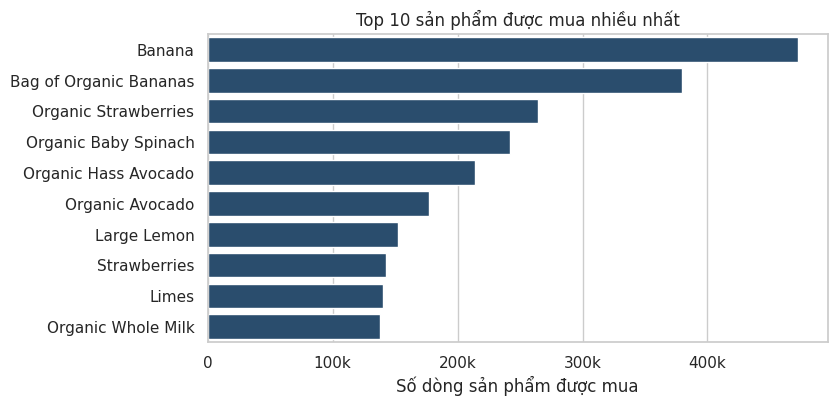

In [27]:
def barh(s, title, fname, figsize=(8, 4)):
    fig, ax = plt.subplots(figsize=figsize)
    sns.barplot(x=s.values, y=s.index, color=C_MAIN, ax=ax)
    ax.set_xlabel('Số dòng sản phẩm được mua'); ax.set_ylabel('')
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(fmt_mk)); ax.set_title(title); savefig(fname)

barh(top_prod.head(10), 'Top 10 sản phẩm được mua nhiều nhất', 'f5_prod')
c = R['conc']; tp = top_prod
note(f'''
**Nhận xét (Hình 5 – sản phẩm).** Dẫn đầu là **{tp.index[0]}** ({tp.iloc[0]:,.0f} lần, {pct(tp.iloc[0]/TOT,2)} tổng dòng), kế đó **{tp.index[1]}** ({tp.iloc[1]:,.0f} lần) và **{tp.index[2]}** ({tp.iloc[2]:,.0f} lần). Mức tập trung ở cấp sản phẩm vừa phải: top 10 chiếm **{pct(c['top10'])}** và top 100 chiếm **{pct(c['top100'])}** số dòng mua, nhưng **1% sản phẩm đứng đầu (~{int(len(pm)*0.01):,} mã) đã chiếm {pct(c['top1pct'])}** tổng lượng mua; có {len(pm) - c['distinct']:,} mã không xuất hiện lần nào trong bảng {TX}.
*Diễn giải bán lẻ:* nhu cầu dồn vào một nhóm nhỏ mã hàng "kéo khách" — phải luôn đủ hàng, đúng chất lượng; phần lớn danh mục còn lại có nhu cầu thấp hơn nhiều nên cần kiểm soát tồn kho và vị trí trưng bày để không chiếm nguồn lực.
''')


**Nhận xét (Hình 6 – gian hàng).** **fresh fruits** (11.2%) và **fresh vegetables** (10.5%) dẫn đầu, tiếp theo là packaged vegetables fruits (5.4%) và yogurt (4.5%). Năm gian hàng đầu bảng chiếm **34.7%** tổng số dòng mua trong tổng 134 gian.
*Diễn giải bán lẻ:* nhu cầu tập trung vào một số gian thiết yếu; nên ưu tiên bố trí, khuyến mãi và quản lý chuỗi lạnh (nếu là hàng tươi/sữa) cho các gian này, và dùng chúng làm "mỏ neo" để gợi ý bán chéo sang gian có nhu cầu thấp hơn.


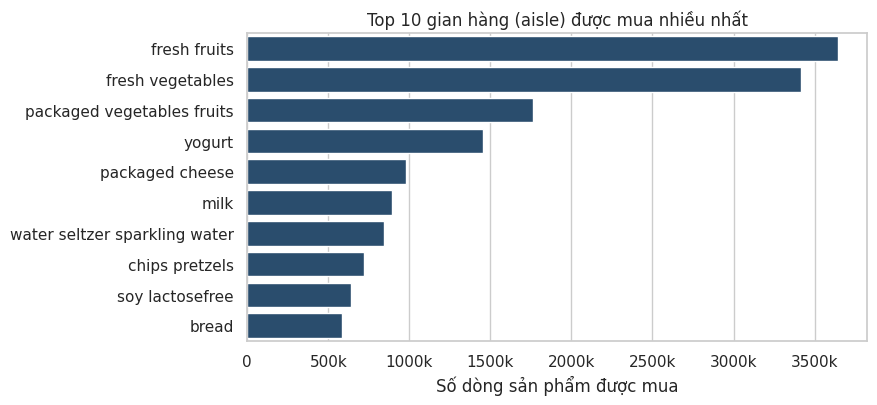

In [28]:
barh(top_aisle.head(10), 'Top 10 gian hàng (aisle) được mua nhiều nhất', 'f6_aisle')
ta = top_aisle
note(f'''
**Nhận xét (Hình 6 – gian hàng).** **{ta.index[0]}** ({pct(ta.iloc[0]/TOT)}) và **{ta.index[1]}** ({pct(ta.iloc[1]/TOT)}) dẫn đầu, tiếp theo là {ta.index[2]} ({pct(ta.iloc[2]/TOT)}) và {ta.index[3]} ({pct(ta.iloc[3]/TOT)}). Năm gian hàng đầu bảng chiếm **{pct(c['top5_aisles'])}** tổng số dòng mua trong tổng {len(aisles)} gian.
*Diễn giải bán lẻ:* nhu cầu tập trung vào một số gian thiết yếu; nên ưu tiên bố trí, khuyến mãi và quản lý chuỗi lạnh (nếu là hàng tươi/sữa) cho các gian này, và dùng chúng làm "mỏ neo" để gợi ý bán chéo sang gian có nhu cầu thấp hơn.
''')


**Nhận xét (Hình 7 – ngành hàng).** **produce** chiếm **29.2%** và **dairy eggs** chiếm **16.7%**, hai ngành cộng lại **45.9%** tổng số dòng mua; tiếp theo là snacks (8.9%), beverages (8.3%) và frozen (6.9%). Cuối bảng là pets, missing, other, bulk (mỗi ngành 0.11%–0.30%). Ngành `missing` chiếm 69,145 dòng (0.21%) và có thêm ngành `other` — đây là sản phẩm **chưa được phân loại**, cần rà soát danh mục.
*Diễn giải bán lẻ:* nên đầu tư vận hành (nguồn hàng, giao nhận lạnh) vào hai ngành đầu bảng; các ngành nhỏ là cơ hội khai thác thêm nhưng cần xét biên lợi nhuận, vì lượng mua chưa nói lên doanh thu.


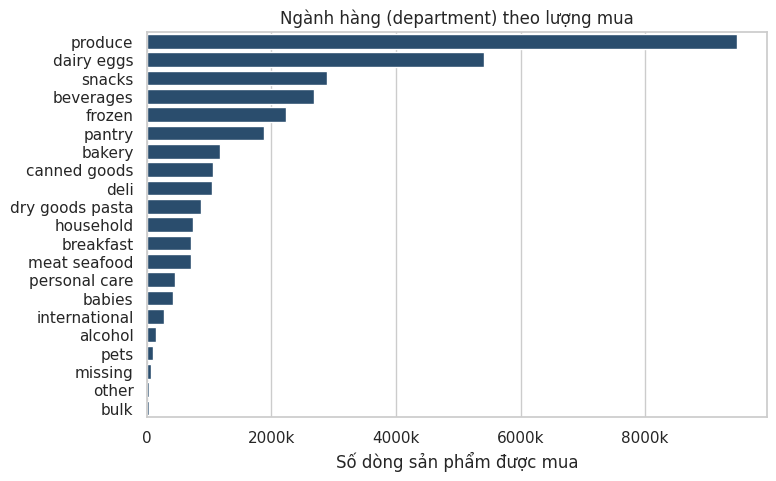

In [29]:
barh(top_dept, 'Ngành hàng (department) theo lượng mua', 'f7_dept', figsize=(8, 5))
td = top_dept; bottom = td.tail(4)
miss_share = float(td.get('missing', 0) / TOT)
note(f'''
**Nhận xét (Hình 7 – ngành hàng).** **{td.index[0]}** chiếm **{pct(td.iloc[0]/TOT)}** và **{td.index[1]}** chiếm **{pct(td.iloc[1]/TOT)}**, hai ngành cộng lại **{pct(c['top2_dept'])}** tổng số dòng mua; tiếp theo là {td.index[2]} ({pct(td.iloc[2]/TOT)}), {td.index[3]} ({pct(td.iloc[3]/TOT)}) và {td.index[4]} ({pct(td.iloc[4]/TOT)}). Cuối bảng là {', '.join(bottom.index)} (mỗi ngành {pct(bottom.min()/TOT,2)}–{pct(bottom.max()/TOT,2)}). Ngành `missing` chiếm {int(td.get('missing', 0)):,} dòng ({pct(miss_share,2)}) và có thêm ngành `other` — đây là sản phẩm **chưa được phân loại**, cần rà soát danh mục.
*Diễn giải bán lẻ:* nên đầu tư vận hành (nguồn hàng, giao nhận lạnh) vào hai ngành đầu bảng; các ngành nhỏ là cơ hội khai thác thêm nhưng cần xét biên lợi nhuận, vì lượng mua chưa nói lên doanh thu.
''')

## 5. Tỷ lệ mua lại

### 5.1 Theo ngành hàng

5 ngành có tỷ lệ mua lại cao nhất và 5 ngành thấp nhất:


,Tỷ lệ mua lại,Số dòng
department,,
dairy eggs,67.0%,"5,414,016"
beverages,65.3%,"2,690,129"
produce,65.0%,"9,479,291"
bakery,62.8%,"1,176,787"
deli,60.8%,"1,051,249"
household,40.2%,"738,666"
missing,39.6%,"69,145"
international,36.9%,"269,253"
pantry,34.7%,"1,875,577"



**Nhận xét (Hình 8).** Tỷ lệ mua lại chung là **59.0%**. Cao nhất là **dairy eggs** (67.0%), **beverages** (65.3%) và **produce** (65.0%); thấp nhất là **personal care** (32.1%), **pantry** (34.7%) và **international** (36.9%). Chênh lệch giữa ngành cao nhất và thấp nhất là **34.9 điểm phần trăm**.
*Diễn giải bán lẻ:* hàng tiêu dùng nhanh, dùng đều đặn là nhóm giữ chân khách, phù hợp với tính năng "mua lại nhanh" và gói đăng ký. Các ngành tỷ lệ mua lại thấp mang tính khám phá hoặc mua không thường xuyên, nên cần khuyến mãi dùng thử và gợi ý theo hồ sơ khách để kích thích lần mua đầu và lần thứ hai.


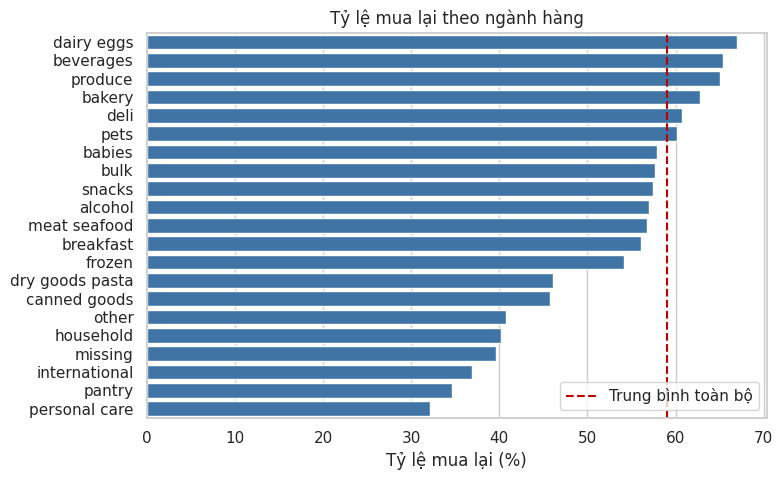

In [30]:
R['reorder_overall'] = float(op['reordered'].mean())
g = pm.groupby('department')[['n', 'r']].sum(); g['rate'] = g['r'] / g['n']
rd = g.sort_values('rate', ascending=False)
R['reorder_dept'] = [[k, float(r['rate']), int(r['n'])] for k, r in rd.iterrows()]

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=rd['rate'].values * 100, y=rd.index, color='#2E75B6', ax=ax)
ax.axvline(R['reorder_overall'] * 100, color=C_ACCENT, ls='--', label='Trung bình toàn bộ')
ax.set_xlabel('Tỷ lệ mua lại (%)'); ax.set_ylabel(''); ax.set_title('Tỷ lệ mua lại theo ngành hàng'); ax.legend()
savefig('f8_rdept')

show = pd.concat([rd.head(5), rd.tail(5)])[['rate', 'n']].rename(columns={'rate': 'Tỷ lệ mua lại', 'n': 'Số dòng'})
print('5 ngành có tỷ lệ mua lại cao nhất và 5 ngành thấp nhất:')
display(show.style.format({'Tỷ lệ mua lại': '{:.1%}', 'Số dòng': '{:,.0f}'}))

hi, lo, ov = rd.head(3), rd.tail(3), R['reorder_overall']
note(f'''
**Nhận xét (Hình 8).** Tỷ lệ mua lại chung là **{pct(ov)}**. Cao nhất là **{hi.index[0]}** ({pct(hi['rate'].iloc[0])}), **{hi.index[1]}** ({pct(hi['rate'].iloc[1])}) và **{hi.index[2]}** ({pct(hi['rate'].iloc[2])}); thấp nhất là **{lo.index[-1]}** ({pct(lo['rate'].iloc[-1])}), **{lo.index[-2]}** ({pct(lo['rate'].iloc[-2])}) và **{lo.index[-3]}** ({pct(lo['rate'].iloc[-3])}). Chênh lệch giữa ngành cao nhất và thấp nhất là **{(rd['rate'].max()-rd['rate'].min())*100:.1f} điểm phần trăm**.
*Diễn giải bán lẻ:* hàng tiêu dùng nhanh, dùng đều đặn là nhóm giữ chân khách, phù hợp với tính năng "mua lại nhanh" và gói đăng ký. Các ngành tỷ lệ mua lại thấp mang tính khám phá hoặc mua không thường xuyên, nên cần khuyến mãi dùng thử và gợi ý theo hồ sơ khách để kích thích lần mua đầu và lần thứ hai.
''')

### 5.2 Theo vị trí thêm vào giỏ (`add_to_cart_order`)

,Mua lại theo vị trí
p1,0.6775
p5,0.6174
p10,0.5510
p20,0.4799
p40,0.4082
corr,-0.1345
first5,0.6554
after20,0.4518
max_pos,145.0000



**Nhận xét (Hình 9).** Tỷ lệ mua lại **giảm đều** theo vị trí thêm vào giỏ: **67.8%** ở vị trí 1, 61.7% ở vị trí 5, 55.1% ở vị trí 10, 48.0% ở vị trí 20 và **40.8%** từ vị trí 40 trở đi. Năm vị trí đầu có tỷ lệ 65.5%, so với 45.2% ở các vị trí sau 20. Hệ số tương quan giữa vị trí và nhãn mua lại là **-0.13** (âm, yếu nhưng nhất quán).
*Diễn giải bán lẻ:* khách thường bỏ vào giỏ món quen thuộc trước, càng về sau là món mới hoặc mua ngẫu hứng. Vì vậy cuối quá trình chọn hàng và bước thanh toán là vị trí tốt để gợi ý sản phẩm mới; còn đầu giỏ nên là danh sách "mua lại nhanh".


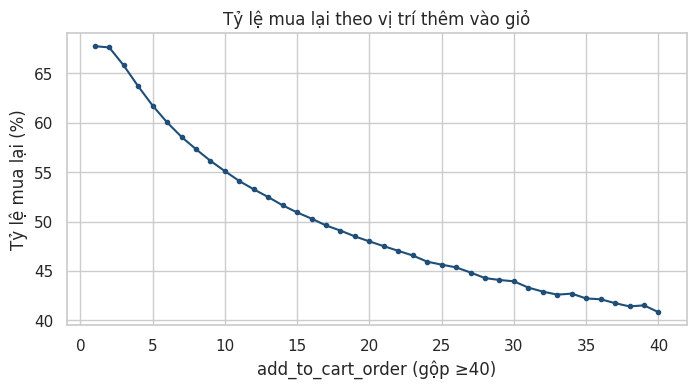

In [31]:
a, rv = op['add_to_cart_order'].to_numpy(), op['reordered'].to_numpy()
pcl = np.minimum(a, 40)
cnt, rr = np.bincount(pcl, minlength=41), np.bincount(pcl, weights=rv, minlength=41)
pos = pd.DataFrame({'mean': rr[1:] / np.maximum(cnt[1:], 1), 'count': cnt[1:]}, index=range(1, 41))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(pos.index, pos['mean'] * 100, marker='o', ms=3, color=C_MAIN)
ax.set_xlabel('add_to_cart_order (gộp ≥40)'); ax.set_ylabel('Tỷ lệ mua lại (%)')
ax.set_title('Tỷ lệ mua lại theo vị trí thêm vào giỏ'); savefig('f9_rpos')

R['pos'] = {**{f'p{p}': float(pos['mean'].loc[p]) for p in (1, 5, 10, 20, 40)}, 'corr': float(np.corrcoef(pcl, rv)[0, 1]),
            'first5': float(rv[a <= 5].mean()), 'after20': float(rv[a > 20].mean()), 'max_pos': int(a.max())}
display(pd.Series(R['pos'], name='Mua lại theo vị trí').to_frame())

q = R['pos']
note(f'''
**Nhận xét (Hình 9).** Tỷ lệ mua lại **giảm đều** theo vị trí thêm vào giỏ: **{pct(q['p1'])}** ở vị trí 1, {pct(q['p5'])} ở vị trí 5, {pct(q['p10'])} ở vị trí 10, {pct(q['p20'])} ở vị trí 20 và **{pct(q['p40'])}** từ vị trí 40 trở đi. Năm vị trí đầu có tỷ lệ {pct(q['first5'])}, so với {pct(q['after20'])} ở các vị trí sau 20. Hệ số tương quan giữa vị trí và nhãn mua lại là **{q['corr']:.2f}** (âm, yếu nhưng nhất quán).
*Diễn giải bán lẻ:* khách thường bỏ vào giỏ món quen thuộc trước, càng về sau là món mới hoặc mua ngẫu hứng. Vì vậy cuối quá trình chọn hàng và bước thanh toán là vị trí tốt để gợi ý sản phẩm mới; còn đầu giỏ nên là danh sách "mua lại nhanh".
''')

## 6. Mức mất cân bằng của nhãn (Bước 5)

Mục này tách hai khái niệm dễ nhầm:

- **Cột `reordered`** của bảng prior cho biết một dòng sản phẩm trong quá khứ có phải là lần mua lặp lại hay không.
- **Nhãn phân lớp của Bước 5** hỏi một sản phẩm người dùng đã từng mua có xuất hiện trong đơn kế tiếp (đơn train) hay không. Nhãn được tạo ở notebook 05 và lưu tại `data/processed/b5/b5_pairs_labels.parquet`.

,Số dòng,Tỷ lệ
reordered,,
0,"13,307,953",41.0%
1,"19,126,536",59.0%


,Nhãn phân lớp Bước 5
n_pairs,"848,233.0000"
n1,"82,657.0000"
s1,0.0974



**Nhận xét (Hình 10).** Trong các dòng sản phẩm prior, reordered = 1 chiếm **59.0%** (19,126,536 dòng) và reordered = 0 chiếm **41.0%** (13,307,953 dòng), tỷ lệ khoảng **1.44 : 1**. Trong bảng train, tỷ lệ này là 59.9%. Có 12.1% số đơn prior không có dòng reordered = 1 nào; con số này gồm cả đơn đầu tiên của mỗi người dùng (luôn có reordered = 0), bỏ các đơn đầu tiên thì còn 6.1%.
Cột reordered không phải nhãn của bài toán phân lớp. Nhãn mua tiếp của Bước 5 chỉ bằng 1 ở **9.74%** trong 848,233 cặp người dùng và sản phẩm, tức mất cân bằng mạnh hơn nhiều; vì vậy Bước 5 dùng F1 và PR-AUC làm độ đo chính và cân bằng lại dữ liệu huấn luyện.


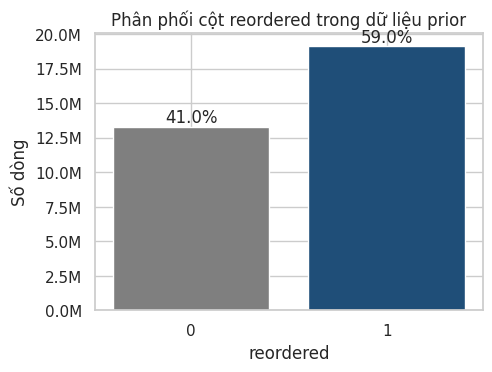

In [32]:
# 6a. Cột reordered của bảng prior
vc = op['reordered'].value_counts().sort_index()
oc = np.bincount(op['order_id'].to_numpy(), weights=op['reordered'].to_numpy()); ob = np.bincount(op['order_id'].to_numpy()); ok = ob > 0
don_khong_mua_lai = set(np.flatnonzero(ok & (oc == 0)))
don_dau = set(orders.loc[(orders['eval_set'] == 'prior') & (orders['order_number'] == 1), 'order_id'])
R['imb'] = {'n0': int(vc[0]), 'n1': int(vc[1]), 's0': float(vc[0] / vc.sum()), 's1': float(vc[1] / vc.sum()),
            'ratio': float(vc[1] / vc[0]), 'orders_no_pos': float((oc[ok] == 0).mean()),
            'orders_no_pos_tru_don_dau': float(len(don_khong_mua_lai - don_dau) / (ok.sum() - len(don_dau))),
            'train_s1': float(op_train['reordered'].mean())}
display(pd.DataFrame({'Số dòng': vc, 'Tỷ lệ': vc / vc.sum()}).rename_axis('reordered').style.format({'Số dòng': '{:,}', 'Tỷ lệ': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.bar(['0', '1'], vc.values, color=[C_GREY, C_MAIN])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v/1e6:,.1f}M'))
for i, v in enumerate(vc.values): ax.text(i, v, f'{v / vc.sum():.1%}', ha='center', va='bottom')
ax.set_xlabel('reordered'); ax.set_title('Phân phối cột reordered trong dữ liệu prior'); ax.set_ylabel('Số dòng'); savefig('f10_imb')

# 6b. Nhãn phân lớp của Bước 5
lab_path = PROC_DIR / 'b5' / 'b5_pairs_labels.parquet'
if lab_path.exists():
    lab = pd.read_parquet(lab_path, columns=['label'])
    R['label_b5'] = {'n_pairs': int(len(lab)), 'n1': int(lab['label'].sum()), 's1': float(lab['label'].mean())}
    display(pd.Series(R['label_b5'], name='Nhãn phân lớp Bước 5').to_frame())
else:
    R['label_b5'] = None
    print('Chưa có tệp nhãn Bước 5; chạy notebook 05 rồi chạy lại ô này.')

m = R['imb']; lb = R['label_b5']
note(f'''
**Nhận xét (Hình 10).** Trong các dòng sản phẩm prior, reordered = 1 chiếm **{pct(m['s1'])}** ({m['n1']:,} dòng) và reordered = 0 chiếm **{pct(m['s0'])}** ({m['n0']:,} dòng), tỷ lệ khoảng **{m['ratio']:.2f} : 1**. Trong bảng train, tỷ lệ này là {pct(m['train_s1'])}. Có {pct(m['orders_no_pos'])} số đơn prior không có dòng reordered = 1 nào; con số này gồm cả đơn đầu tiên của mỗi người dùng (luôn có reordered = 0), bỏ các đơn đầu tiên thì còn {pct(m['orders_no_pos_tru_don_dau'])}.
{(f"Cột reordered không phải nhãn của bài toán phân lớp. Nhãn mua tiếp của Bước 5 chỉ bằng 1 ở **{pct(lb['s1'], 2)}** trong {lb['n_pairs']:,} cặp người dùng và sản phẩm, tức mất cân bằng mạnh hơn nhiều; vì vậy Bước 5 dùng F1 và PR-AUC làm độ đo chính và cân bằng lại dữ liệu huấn luyện.") if lb else "Chưa có nhãn Bước 5 để so sánh."}
''')


## 7. Tổng hợp nhận xét và hạn chế

In [33]:
u, x, b, c, q, m = R['upu'], R['days'], R['basket'], R['conc'], R['pos'], R['imb']
topd = R['top_dept']; rate_d = {k: r for k, r, _ in R['reorder_dept']}
note(f'''
### Kết luận chính
1. **Khách trung thành tạo phần lớn số đơn:** nhóm trên 20 đơn chỉ {pct(u['share_gt20_users'])} người dùng nhưng tạo {pct(u['share_gt20_orders'])} số đơn.
2. **Thời điểm:** nhu cầu cao nhất ở hai ngày `order_dow` {', '.join(map(str, sorted(R['heat']['dow_share'], key=R['heat']['dow_share'].get, reverse=True)[:2]))} và khung 9h–16h ({pct(R['heat']['share_9_16'])} số đơn); chu kỳ mua theo tuần rất rõ (đỉnh 7, 14, 21, 28 ngày, cộng lại {pct(x['weekly_share'])} số đơn).
3. **Dữ liệu bị chặn trần:** đỉnh ngày 30 ({pct(x['s30'])} số đơn, gấp {x['r30_29']:.1f} lần ngày 29) là do censoring, phải diễn giải là "từ 30 ngày trở lên".
4. **Giỏ hàng:** trung bình {b['mean']:.2f}, trung vị {b['median']:.0f} sản phẩm; {pct(b['le5'])} đơn có từ 5 sản phẩm trở xuống.
5. **Danh mục:** {topd[0][0]} và {topd[1][0]} chiếm {pct(c['top2_dept'])} lượt mua (tỷ lệ mua lại {pct(rate_d[topd[0][0]])} và {pct(rate_d[topd[1][0]])}, so với mức chung {pct(R['reorder_overall'])}); 1% sản phẩm đầu chiếm {pct(c['top1pct'])} lượng mua.
6. **Vị trí trong giỏ:** tỷ lệ mua lại giảm từ {pct(q['p1'])} (vị trí 1) xuống {pct(q['p40'])} (vị trí ≥40) → gợi ý cách bố trí danh sách mua lại và gợi ý sản phẩm mới.
7. **Cột reordered và nhãn phân lớp:** cột reordered chênh lệch nhẹ ({pct(m['s1'])} / {pct(m['s0'])}), nhưng nhãn mua tiếp của Bước 5 chênh lệch mạnh ({pct(R['label_b5']['s1'], 2) if R['label_b5'] else 'chưa có'} lớp 1).

### Hạn chế
- "Mua nhiều" đo bằng số dòng sản phẩm, không phải doanh thu hay biên lợi nhuận; dữ liệu không có giá bán.
- Dữ liệu chỉ có mã `order_dow`, không có ngày thật; khoảng cách giữa hai đơn bị chặn trần ở 30 ngày.
''')

def _default(o):
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.integer):  return int(o)
    if isinstance(o, np.bool_):    return bool(o)
    return str(o)
out = OUT_DIR / 'eda_summary.json'
json.dump({'transaction_table': TX, **R}, open(out, 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=_default)
print('Đã lưu:', out)


### Kết luận chính
1. **Khách trung thành tạo phần lớn số đơn:** nhóm trên 20 đơn chỉ 24.6% người dùng nhưng tạo 58.7% số đơn.
2. **Thời điểm:** nhu cầu cao nhất ở hai ngày `order_dow` 0, 1 và khung 9h–16h (64.9% số đơn); chu kỳ mua theo tuần rất rõ (đỉnh 7, 14, 21, 28 ngày, cộng lại 15.3% số đơn).
3. **Dữ liệu bị chặn trần:** đỉnh ngày 30 (11.5% số đơn, gấp 19.2 lần ngày 29) là do censoring, phải diễn giải là "từ 30 ngày trở lên".
4. **Giỏ hàng:** trung bình 10.09, trung vị 8 sản phẩm; 31.1% đơn có từ 5 sản phẩm trở xuống.
5. **Danh mục:** produce và dairy eggs chiếm 45.9% lượt mua (tỷ lệ mua lại 65.0% và 67.0%, so với mức chung 59.0%); 1% sản phẩm đầu chiếm 42.8% lượng mua.
6. **Vị trí trong giỏ:** tỷ lệ mua lại giảm từ 67.8% (vị trí 1) xuống 40.8% (vị trí ≥40) → gợi ý cách bố trí danh sách mua lại và gợi ý sản phẩm mới.
7. **Cột reordered và nhãn phân lớp:** cột reordered chênh lệch nhẹ (59.0% / 41.0%), nhưng nhãn mua tiếp của Bước 5 chênh lệch mạnh (9.74% lớp 1).

### Hạn chế
- "Mua nhiều" đo bằng số dòng sản phẩm, không phải doanh thu hay biên lợi nhuận; dữ liệu không có giá bán.
- Dữ liệu chỉ có mã `order_dow`, không có ngày thật; khoảng cách giữa hai đơn bị chặn trần ở 30 ngày.


Đã lưu: /content/drive/MyDrive/Nhom04_ADM/repo/outputs/step1/eda_summary.json


## 8. Đối chiếu với báo cáo (Chương 4 mục 2)

In [34]:
u, x, b, c, q, m = R['upu'], R['days'], R['basket'], R['conc'], R['pos'], R['imb']
rate_d = {k: r for k, r, _ in R['reorder_dept']}
BAO_CAO = [  # (chỉ tiêu, giá trị tính được, số trong báo cáo, sai số cho phép)
    ("Số đơn trung bình mỗi người dùng", round(u['mean'], 2), 16.59, 0.005),
    ("Hệ số bất đối xứng số đơn", round(u['skew'], 2), 2.40, 0.005),
    ("Số người chạm trần 100 đơn", u['n_at_max'], 1374, 0),
    ("Nhóm trên 20 đơn: % người dùng", round(100 * u['share_gt20_users'], 1), 24.6, 0.05),
    ("Nhóm trên 20 đơn: % số đơn", round(100 * u['share_gt20_orders'], 1), 58.7, 0.05),
    ("Ô nhiệt lớn nhất (order_dow 1, 10 giờ)", R['heat']['top3'][0][2], 55671, 0),
    ("Khung 9 đến 16 giờ: % số đơn", round(100 * R['heat']['share_9_16'], 1), 64.9, 0.05),
    ("Giỏ hàng trung bình", round(b['mean'], 2), 10.09, 0.005),
    ("Giỏ hàng trung vị", b['median'], 8, 0),
    ("Giỏ hàng lớn nhất", b['max'], 145, 0),
    ("Đơn có từ 5 sản phẩm trở xuống (%)", round(100 * b['le5'], 1), 31.1, 0.05),
    ("Top 10 sản phẩm (%)", round(100 * c['top10'], 1), 7.2, 0.05),
    ("Top 100 sản phẩm (%)", round(100 * c['top100'], 1), 23.1, 0.05),
    ("1% sản phẩm đầu (%)", round(100 * c['top1pct'], 1), 42.8, 0.05),
    ("Năm gian hàng đầu (%)", round(100 * c['top5_aisles'], 1), 34.7, 0.05),
    ("produce và dairy eggs (%)", round(100 * c['top2_dept'], 1), 45.9, 0.05),
    ("Tỷ lệ mua lại chung (%)", round(100 * R['reorder_overall'], 1), 59.0, 0.05),
    ("Mua lại của produce (%)", round(100 * rate_d['produce'], 1), 65.0, 0.05),
    ("Mua lại của dairy eggs (%)", round(100 * rate_d['dairy eggs'], 1), 67.0, 0.05),
    ("Mua lại ở vị trí 1 (%)", round(100 * q['p1'], 1), 67.8, 0.05),
    ("Mua lại từ vị trí 40 (%)", round(100 * q['p40'], 1), 40.8, 0.05),
    ("Tương quan vị trí và reordered", round(q['corr'], 2), -0.13, 0.005),
    ("Số dòng reordered = 1", m['n1'], 19126536, 0),
    ("Số dòng reordered = 0", m['n0'], 13307953, 0),
    ("Đơn không có dòng reordered = 1 (%)", round(100 * m['orders_no_pos'], 1), 12.1, 0.05),
]
if R['label_b5']:
    BAO_CAO.append(("Nhãn Bước 5: % lớp 1", round(100 * R['label_b5']['s1'], 2), 9.74, 0.005))
bang = pd.DataFrame([{"chi_tieu": t, "thuc_te": v, "bao_cao": bc, "khop": abs(float(v) - float(bc)) <= tol}
                     for t, v, bc, tol in BAO_CAO]).astype({"thuc_te": object, "bao_cao": object})
display(bang)
print(f"Đối chiếu với báo cáo: {int(bang['khop'].sum())}/{len(bang)} chỉ tiêu khớp")
if not bang['khop'].all():
    print("Có chỉ tiêu lệch: sửa số trong báo cáo theo notebook, hoặc kiểm tra lại dữ liệu đầu vào.")


,chi_tieu,thuc_te,bao_cao,khop
0,Số đơn trung bình mỗi người dùng,16.5900,16.5900,True
1,Hệ số bất đối xứng số đơn,2.4000,2.4000,True
2,Số người chạm trần 100 đơn,"1,374.0000","1,374.0000",True
3,Nhóm trên 20 đơn: % người dùng,24.6000,24.6000,True
4,Nhóm trên 20 đơn: % số đơn,58.7000,58.7000,True
5,"Ô nhiệt lớn nhất (order_dow 1, 10 giờ)","55,671.0000","55,671.0000",True
6,Khung 9 đến 16 giờ: % số đơn,64.9000,64.9000,True
7,Giỏ hàng trung bình,10.0900,10.0900,True
8,Giỏ hàng trung vị,8.0000,8.0000,True
9,Giỏ hàng lớn nhất,145.0000,145.0000,True


Đối chiếu với báo cáo: 26/26 chỉ tiêu khớp
